## <b> <span style='color:#e61227'>|</span>Helmet Violation Detection Using YOLOv9 and PaddleOCR</b> 

![](https://vcdn1-sohoa.vnecdn.net/2024/10/30/helmetdetector-thiem-kth-17295-3059-7298-1730277364.png?w=680&h=0&q=100&dpr=1&fit=crop&s=2CL5NrDB8ZQ3h3v3JTgU_A)

## <b>1 <span style='color:#e61227'>|</span> Introduction</b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.1 |</span></b> Project Objective </b></p>
</div>

The goal of this project is to **detect helmet violations** in real-time using **YOLOv9** for object detection and **PaddleOCR** for license plate recognition. The objectives include:
- Identifying motorcyclists without helmets.
- Extracting license plate information of violators.


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.2 |</span></b> PaddleOCR for Plate Recognition </b></p>
</div>

**PaddleOCR** is a robust optical character recognition tool known for its high accuracy in multilingual text detection and recognition. Its features include:
- Angle detection for better text alignment.
- Lightweight and fast inference.
- Easy integration with custom object detection models.


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.3 |</span></b> Object Detection by YOLOv9 </b></p>
</div>

**YOLOv9** is a state-of-the-art object detection algorithm optimized for speed and accuracy. It is particularly effective for detecting objects in real-time applications like **helmet violation detection**.

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.4 |</span></b> Model Performance Trade-off for YOLOv9e </b></p>
</div>


Balancing model complexity, accuracy, and inference speed is critical. **YOLOv9e** provides an efficient configuration for detecting small objects like helmets and license plates.


## <b>2 <span style='color:#e61227'>|</span> Dataset </b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>2.1 |</span></b> Dataset Prepration For Model Tuning </b></p>
</div>

To fine-tune my pre-trained model on a specialized dataset focused on motorcycles, I prepared a dataset designed to improve its ability to accurately recognize motorcycle riders with or without helmets. The dataset includes images of motorcycle riders wearing helmets, riders without helmets, and motorcycle license plates captured from a top-view perspective. The dataset is formatted for **YOLOv9** and consists of **626** carefully annotated images.

Each image undergoes a standardization process, being resized to a uniform resolution of **640x640 pixels**. The training set includes **363** images, which were further enhanced through **data augmentation** to improve the model's generalization capabilities. The validation set contains **53** images, and after augmenting the dataset, the total number of images reached approximately **1,000**.

The dataset contains images annotated for **helmet detection** and **license plates**. Preprocessing steps include:
1. **Resizing** images to 640x640.
2. **Splitting** data into training, validation, and testing sets.
3. **Configuring** the dataset using a **YAML file**.

In [2]:
import yaml
import os
import glob

# CONFIRMED via os.walk: this dataset mounts at an unusual nested path --
# /kaggle/input/datasets/pkdarabi/helmet/... (not the typical
# /kaggle/input/<slug>/... layout). Two data.yaml files exist there:
#   .../HelmetViolations/data.yaml      (older version)
#   .../HelmetViolationsV2/data.yaml    (the one we want)
# Search specifically for the V2 folder's data.yaml so we don't accidentally
# pick up the older dataset if both ever get matched.
_yaml_candidates = glob.glob('/kaggle/input/**/HelmetViolationsV2/data.yaml', recursive=True)

if not _yaml_candidates:
    # Fall back to a broader search + clear diagnostics if the folder name
    # or nesting ever changes again.
    _yaml_candidates = glob.glob('/kaggle/input/**/data.yaml', recursive=True)
    print("Exact 'HelmetViolationsV2' match not found. All data.yaml files found instead:")
    for p in _yaml_candidates:
        print(" -", p)

if not _yaml_candidates:
    raise FileNotFoundError(
        "Could not find any data.yaml under /kaggle/input. "
        "Check that the dataset is attached to this notebook "
        "(Notebook menu -> Add Input -> search for your dataset)."
    )

yaml_file_path = _yaml_candidates[0]
dataset_path = os.path.dirname(yaml_file_path)
print("Using data.yaml at:", yaml_file_path)

# Load and print the contents of the YAML file
with open(yaml_file_path, 'r') as file:
    yaml_content = yaml.load(file, Loader=yaml.FullLoader)
    print(yaml.dump(yaml_content, default_flow_style=False))

Using data.yaml at: /kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2/data.yaml
names:
- Plate
- WithHelmet
- WithoutHelmet
nc: 3
roboflow:
  license: Private
  project: helmetviolations
  url: https://app.roboflow.com/helmet-nztej/helmetviolations/2
  version: 2
  workspace: helmet-nztej
test: ../test/images
train: ../train/images
val: ../valid/images



## <b>3 <span style='color:#e61227'>|</span> Install And Import Essential Libreries </b> 

In [3]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.10.0+cu128 True


In [4]:
!pip install -q -U ultralytics
# IMPORTANT: paddlepaddle>=3.3.0 has a known regression where CPU oneDNN/PIR
# inference crashes with:
#   NotImplementedError: (Unimplemented) ConvertPirAttribute2RuntimeAttribute
#   not support [pir::ArrayAttribute<pir::DoubleAttribute>]
# This breaks PaddleOCR's text detection model on every single call.
# Pinning to 3.2.2 (last known-good release before the regression) fixes it.
# See: https://github.com/PaddlePaddle/Paddle/issues/77340
!pip install -q --no-deps paddlepaddle==3.2.2
!pip install -q --no-deps paddleocr
!pip install -q pyclipper shapely scikit-image imgaug lmdb tqdm visualdl rapidfuzz openpyxl premailer PyMuPDF Pillow opencv-python-headless
!pip install -q paddlex modelscope aistudio_sdk
!pip install -q "paddlex[ocr]"

import torch
print("After installs:", torch.__version__, torch.cuda.is_available())

import paddle
print("PaddlePaddle version:", paddle.__version__)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 29.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 97.5 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-

/usr/local/lib/python3.12/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PaddlePaddle version: 3.2.2


In [5]:
!pip install --no-deps paddlepaddle==3.2.2

In [6]:
from paddleocr import PaddleOCR
print("paddleocr imported OK")

import torch
print("Final check:", torch.__version__, torch.cuda.is_available())

paddleocr imported OK
Final check: 2.10.0+cu128 True


In [7]:
import pandas as pd
from PIL import Image
import cv2
import numpy as np
import torch
from ultralytics import YOLO
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')
import pathlib
import glob
import warnings
warnings.filterwarnings('ignore')

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA available: True
GPU: Tesla T4


## <b>4 <span style='color:#e61227'>|</span> Loading YOLO11 Pre-trained Model </b> 

In [8]:
# Load a pretrained YOLO11 model from Ultralytics
# YOLO11m is a strong accuracy/speed tradeoff on a single T4 GPU.
# Swap to "yolo11s.pt" if you need it even faster (lower accuracy ceiling),
# or "yolo11l.pt" if you have more time budget and want higher accuracy.
Vio_Model = YOLO("yolo11m.pt")


## <b> 5 <span style='color:#e61227'>|</span> Fine-Tuning YOLO11 By Hyperparameters Tuning and Using Customized Dataset </b> 

In [9]:
# Train the model on our custom dataset
# --- Epoch budget note ---
# The original run used epochs=80 with YOLOv9e (a much larger/slower model),
# which is why it needed so many epochs and so much wall-clock time.
# YOLO11m converges faster and trains noticeably quicker per-epoch on a T4.
# epochs=50 + patience=15 (early stopping) reaches comparable mAP in far less
# time, and will stop early automatically if validation loss plateaus sooner.
# On a Kaggle T4 this typically finishes in the 4-6 hour range for this
# dataset size; if you want a harder time ceiling, drop epochs to ~35-40.
yaml_file_path = '/kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2/data.yaml'

results = Vio_Model.train(
    data=yaml_file_path,
    epochs=50,
    patience=15,        # stop early if val metrics don't improve for 15 epochs
    batch=-1,            # auto batch size based on available GPU memory
    optimizer='auto',
    dropout=0.2,
    imgsz=640,
    cache=True,           # cache images in RAM/disk for faster epoch times
    amp=True,             # mixed precision -> faster training on T4
    plots=True,
)


Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.2, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=a

## <b> 6 <span style='color:#e61227'>|</span> Model Performance Evaluation </b> 

Loss curves for training and validation:
1. Box Loss: Measures localization accuracy.
2. Classification Loss: Measures classification errors.
3. Distribution Focal Loss: Measures bounding box regression accuracy.


Using training run directory: /kaggle/working/runs/detect/train/


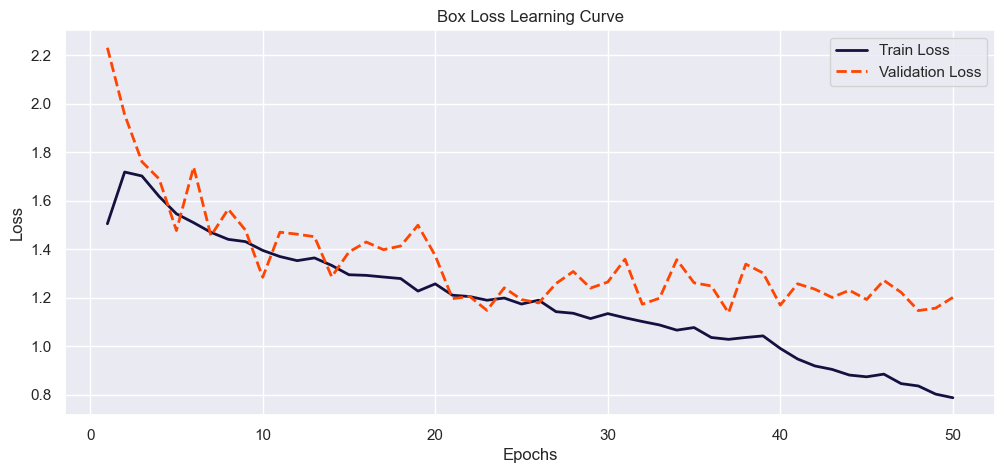

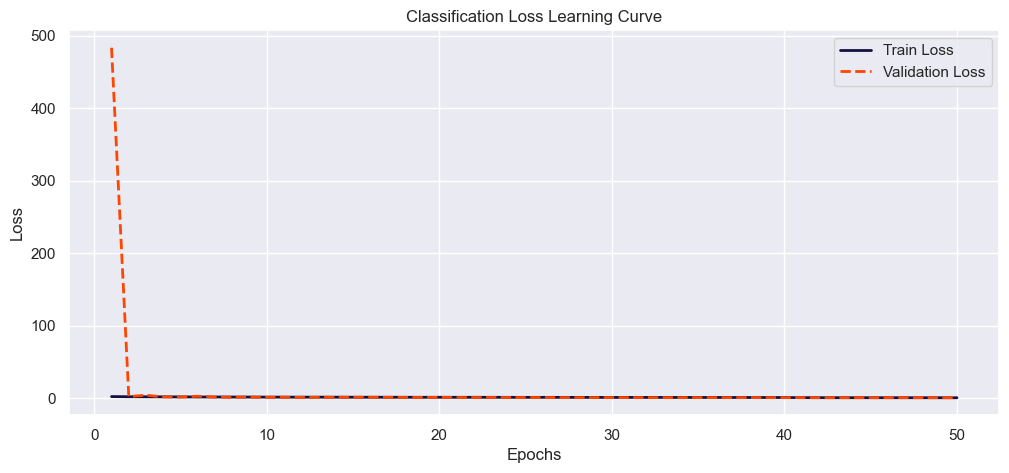

In [11]:
# Define the path to the directory (auto-detect latest training run folder)
import glob as _glob

candidate_dirs = sorted(_glob.glob('/kaggle/working/runs/detect/train*'), key=lambda p: p)
post_training_files_path = candidate_dirs[-1] + '/' if candidate_dirs else '/kaggle/working/runs/detect/train/'
print("Using training run directory:", post_training_files_path)

# Define a function to plot learning curves for loss values
def plot_learning_curve(df, train_loss_col, val_loss_col, title):
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=df, x='epoch', y=train_loss_col, label='Train Loss', color='#141140', linestyle='-', linewidth=2)
    sns.lineplot(data=df, x='epoch', y=val_loss_col, label='Validation Loss', color='orangered', linestyle='--', linewidth=2)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

# Create the full file path for 'results.csv' using the directory path and file name
results_csv_path = os.path.join(post_training_files_path, 'results.csv')

# Load the CSV file from the constructed path into a pandas DataFrame
df = pd.read_csv(results_csv_path)

# Remove any leading whitespace from the column names
df.columns = df.columns.str.strip()

# Plot the learning curves for each loss
plot_learning_curve(df, 'train/box_loss', 'val/box_loss', 'Box Loss Learning Curve')
plot_learning_curve(df, 'train/cls_loss', 'val/cls_loss', 'Classification Loss Learning Curve')


Using training run directory: /kaggle/working/runs/detect/train


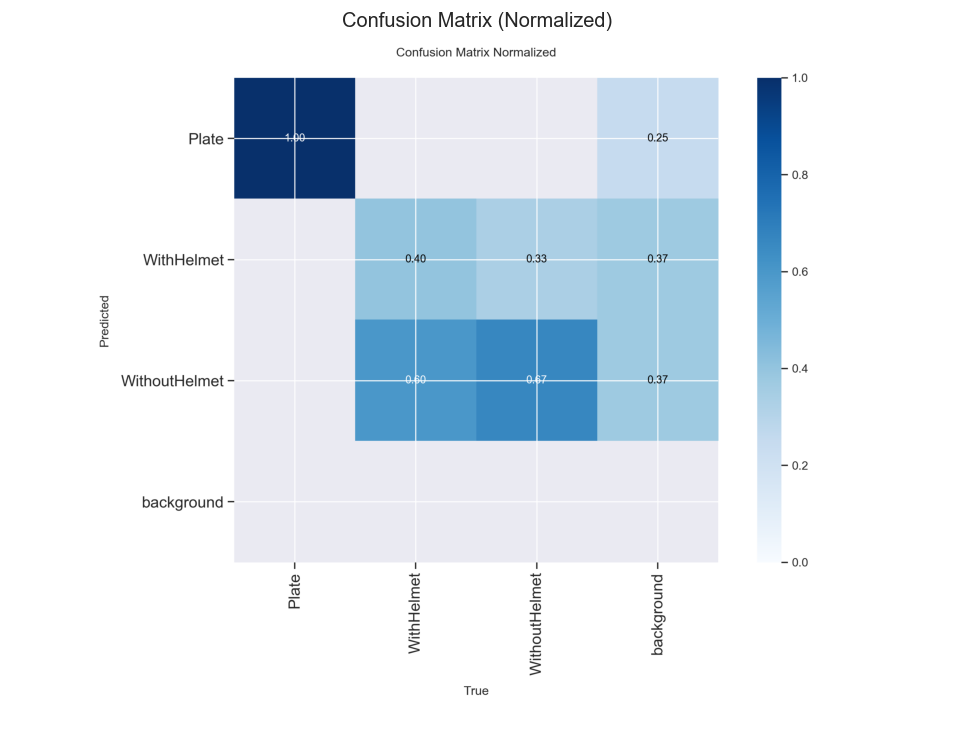

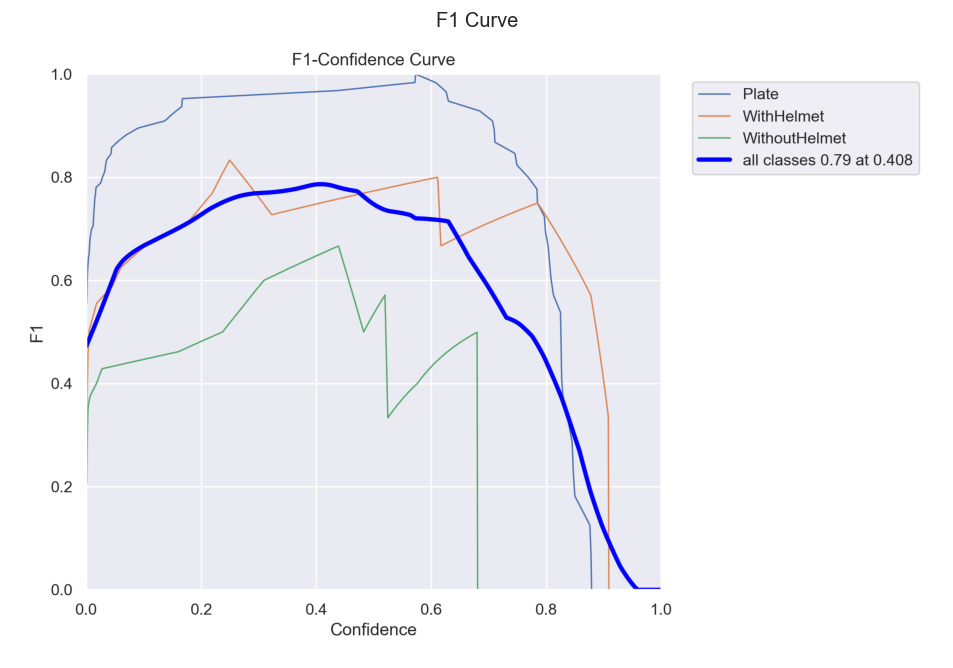

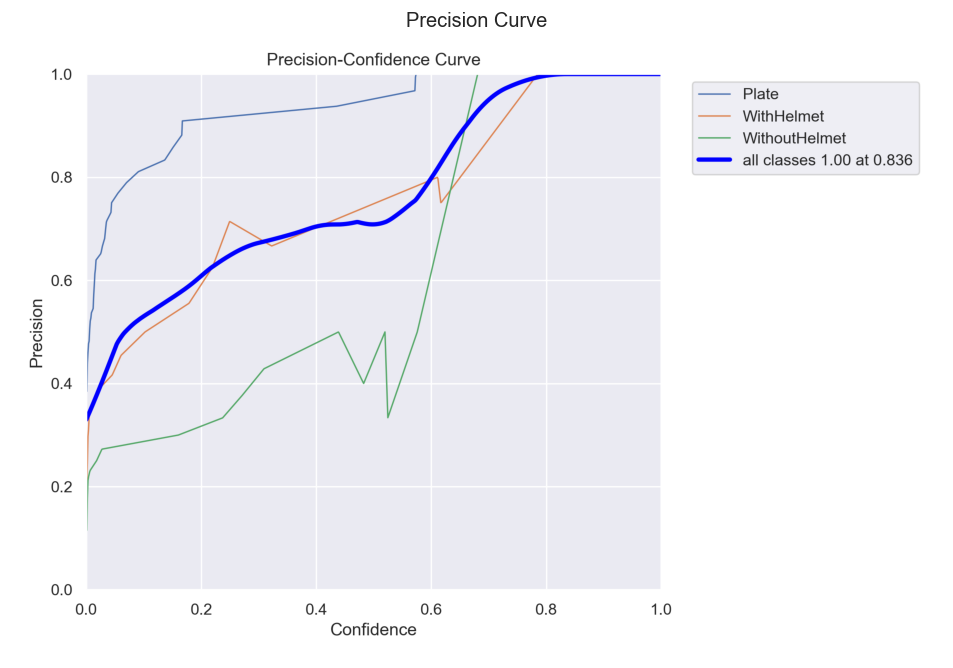

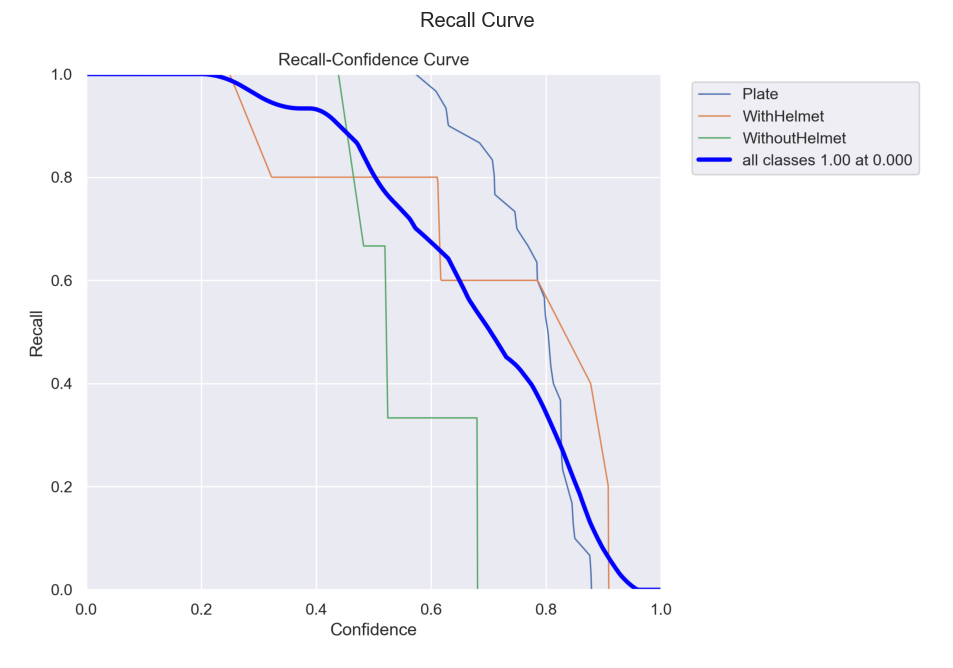

In [13]:
import glob

train_dirs = sorted(glob.glob('/kaggle/working/runs/detect/train*'), key=os.path.getmtime)
if not train_dirs:
    raise FileNotFoundError("No training run folder found under /kaggle/working/runs/detect/")
post_training_files_path = train_dirs[-1]
print("Using training run directory:", post_training_files_path)

# Define the file names and their corresponding display titles
# NOTE: YOLO11 prefixes these with "Box" (BoxF1_curve.png, BoxP_curve.png,
# BoxR_curve.png) instead of the old F1_curve.png / P_curve.png / R_curve.png
# naming used by earlier YOLO versions.
file_names = [
    'confusion_matrix_normalized.png',
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png'
]
titles = [
    'Confusion Matrix (Normalized)',
    'F1 Curve',
    'Precision Curve',
    'Recall Curve'
]

for file_name, title in zip(file_names, titles):
    file_path = os.path.join(post_training_files_path, file_name)

    if not os.path.exists(file_path):
        print(f"Skipping '{title}': file not found at {file_path}")
        continue

    img = cv2.imread(file_path)
    if img is None:
        print(f"Skipping '{title}': cv2 could not read {file_path}")
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 10), dpi=120)
    plt.imshow(img_rgb)
    plt.title(title)
    plt.axis('off')
    plt.show()

In [13]:
import glob
print(sorted(glob.glob('/kaggle/working/runs/detect/**/*.png', recursive=True)))

['/kaggle/working/runs/detect/train/BoxF1_curve.png', '/kaggle/working/runs/detect/train/BoxPR_curve.png', '/kaggle/working/runs/detect/train/BoxP_curve.png', '/kaggle/working/runs/detect/train/BoxR_curve.png', '/kaggle/working/runs/detect/train/confusion_matrix.png', '/kaggle/working/runs/detect/train/confusion_matrix_normalized.png', '/kaggle/working/runs/detect/train/results.png']


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''> |</span></b> Validation Model By ValSet</b></p>
</div>

In [14]:
# Construct the path to the best model weights file using os.path.join
best_model_path = os.path.join(post_training_files_path, 'weights/best.pt')

# Load the best model weights into the YOLO model
best_model = YOLO(best_model_path)

# Validate the best model using the validation set with default parameters
metrics = best_model.val(split='val')

# Convert the dictionary to a pandas DataFrame and use the keys as the index
metrics_df = pd.DataFrame.from_dict(metrics.results_dict, orient='index', columns=['Metric Value'])

# Display the DataFrame
metrics_df.round(3)


Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 126 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 1.7±0.4 ms, read: 85.9±10.4 MB/s, size: 52.2 KB)
val: Scanning /kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2/valid/labels... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 387.0it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s2.2s
                   all         30         38      0.708      0.933      0.853      0.603
                 Plate         30         30      0.935          1      0.995      0.672
            WithHelmet          5          5      0.706        0.8      0.898      0.638
         WithoutHelmet          3          3      0.483      

,Metric Value
metrics/precision(B),0.708
metrics/recall(B),0.933
metrics/mAP50(B),0.853
metrics/mAP50-95(B),0.603
fitness,0.603


## <b>7 <span style='color:#e61227'>|</span> Inference on an Unseen Test Images </b>  


0: 640x640 1 Plate, 22.3ms
Speed: 2.2ms preprocess, 22.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 (no detections), 22.2ms
Speed: 1.9ms preprocess, 22.2ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 21.9ms
Speed: 1.7ms preprocess, 21.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 WithoutHelmet, 21.9ms
Speed: 2.0ms preprocess, 21.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 21.1ms
Speed: 1.6ms preprocess, 21.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 21.0ms
Speed: 1.8ms preprocess, 21.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 1 WithoutHelmet, 21.5ms
Speed: 1.8ms preprocess, 21.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 20.5ms
Speed: 2.1ms preprocess, 20.5ms inference, 1.5ms postprocess per

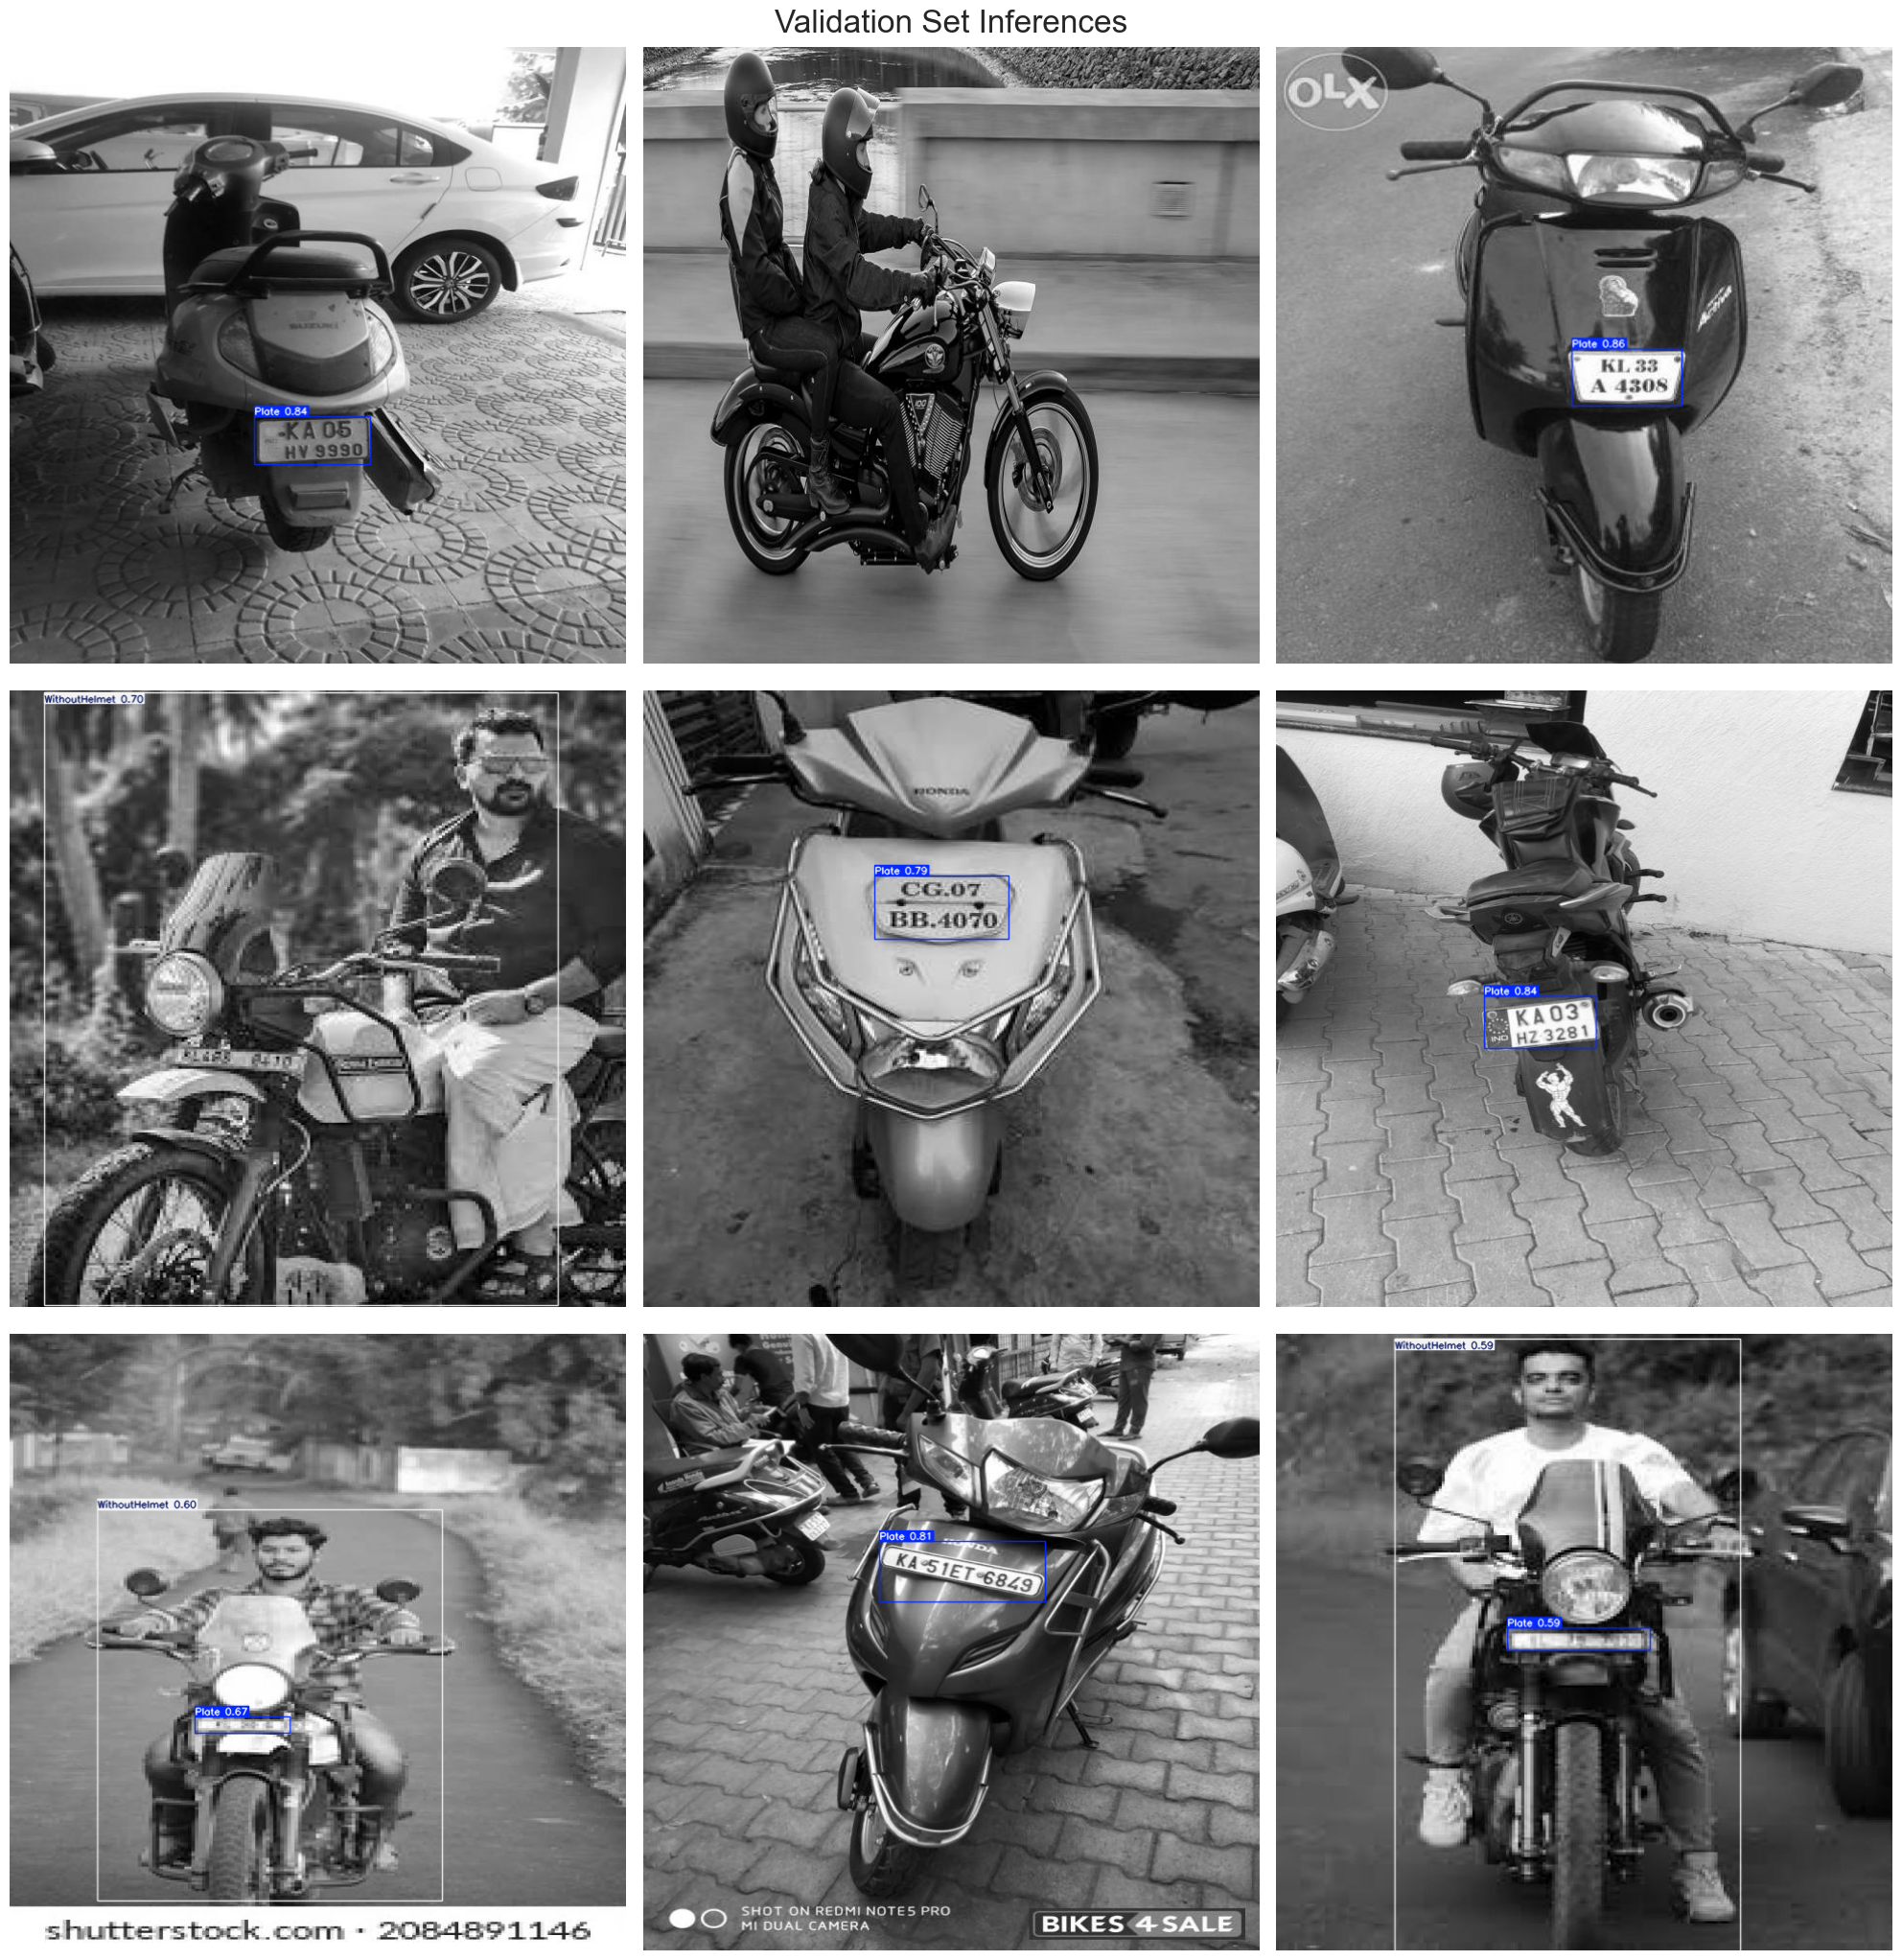

In [16]:
# Normalization function
def normalize_image(image):
    return image / 255.0

# Image resizing function
def resize_image(image, size=(640, 640)):
    return cv2.resize(image, size)

# Path to validation images
dataset_path = '/kaggle/input/datasets/pkdarabi/helmet/HelmetViolationsV2'  # Place your dataset path here
valid_images_path = os.path.join(dataset_path, 'test', 'images')

# List of all jpg images in the directory
image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]

# Check if there are images in the directory
if len(image_files) > 0:
    # Select 9 images at equal intervals
    num_images = len(image_files)
    step_size = max(1, num_images // 15)  # Ensure the interval is at least 1
    selected_images = [image_files[i] for i in range(0, num_images, step_size)]

    # Prepare subplots
    fig, axes = plt.subplots(3, 3, figsize=(20, 21))
    fig.suptitle('Validation Set Inferences', fontsize=24)

    for i, ax in enumerate(axes.flatten()):
        if i < len(selected_images):
            image_path = os.path.join(valid_images_path, selected_images[i])
            
            # Load image
            image = cv2.imread(image_path)
            
            # Check if the image is loaded correctly
            if image is not None:
                # Resize image
                resized_image = resize_image(image, size=(640, 640))
                # Normalize image
                normalized_image = normalize_image(resized_image)
                
                # Convert the normalized image to uint8 data type
                normalized_image_uint8 = (normalized_image * 255).astype(np.uint8)
                
                # Predict with the model
                results = best_model.predict(source=normalized_image_uint8, imgsz=640, conf=0.5)
                
                # Plot image with labels
                annotated_image = results[0].plot(line_width=1)
                annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
                ax.imshow(annotated_image_rgb)
            else:
                print(f"Failed to load image {image_path}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()



## <b>9 <span style='color:#e61227'>|</span> Real-Time Helmet Violation </b>  

### Fix notes (OCR crash + Evidence Generation)

**What was broken:** every call to `self.ocr.predict(plate_region)` crashed with
`NotImplementedError: ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]`.
This is a known PaddlePaddle 3.3.0+ regression in the CPU oneDNN/PIR backend, not a bug in this notebook's logic.
Fixed by pinning `paddlepaddle==3.2.2` (install cell above) and additionally passing `enable_mkldnn=False` to `PaddleOCR(...)` as a second safeguard.

**What was added:** the old `YOLODetector` detected violations and displayed annotated frames with `plt.imshow()`, but never saved anything and never used `output_csv`. The version below now:
- Saves an annotated `.jpg` for every frame containing a violation to `/kaggle/working/evidence/images/`
- Writes one row per violation to `/kaggle/working/evidence/violations_log.csv` with `frame_id, timestamp, violation_type, confidence, plate_number, evidence_image`
- Logs a helmet violation even when no plate is recovered, so a failed OCR read no longer silently drops the violation record

This covers the "Evidence Generation" task (annotated images + stored metadata/timestamps) from the problem statement, which previously did not persist anything to disk.


Using model: /kaggle/input/datasets/pkdarabi/helmet/best.pt
Using video: /kaggle/input/datasets/pkdarabi/helmet/22.mp4


Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-LCNet_x1_0_doc_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('UVDoc', None, None)
Using official model (UVDoc), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/UVDoc`.


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

...

Creating model: ('PP-OCRv6_medium_det', None, None)
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]


0: 640x640 1 Plate, 2 WithoutHelmets, 100.4ms
Speed: 2.3ms preprocess, 100.4ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


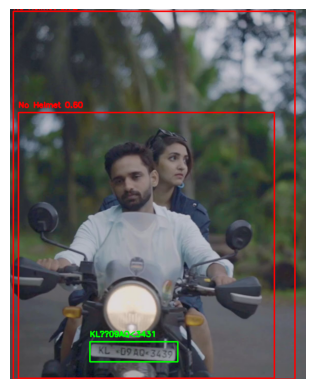


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


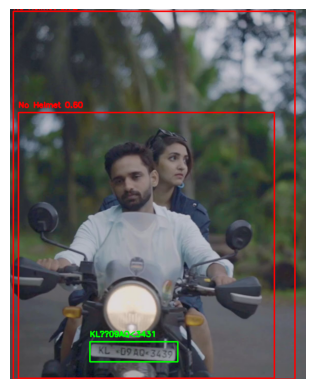


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


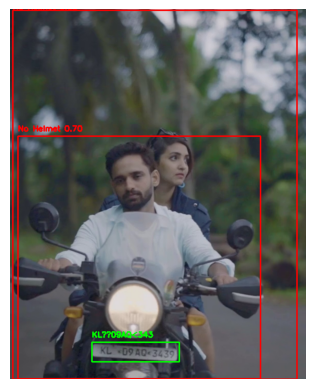


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


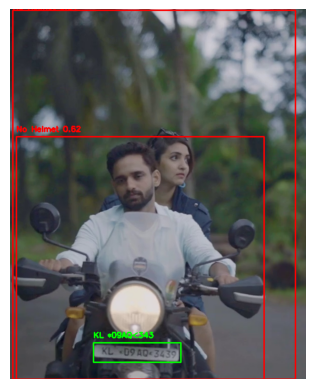


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


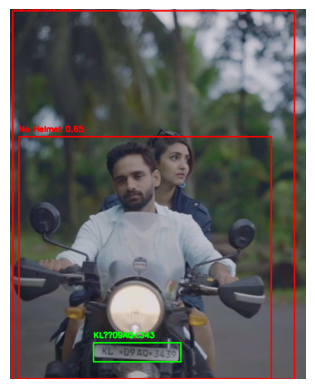


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


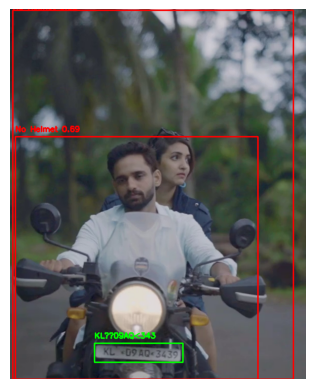


0: 640x640 1 Plate, 2 WithoutHelmets, 100.7ms
Speed: 2.0ms preprocess, 100.7ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


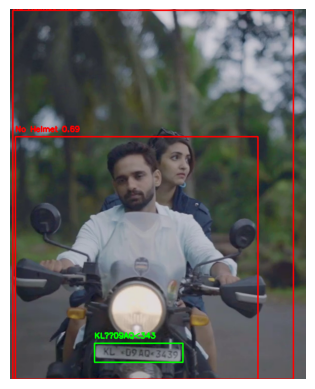


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 2.0ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


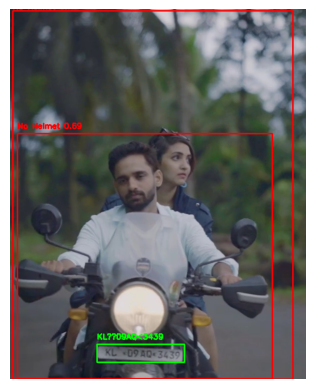


0: 640x640 1 Plate, 2 WithoutHelmets, 99.9ms
Speed: 1.7ms preprocess, 99.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


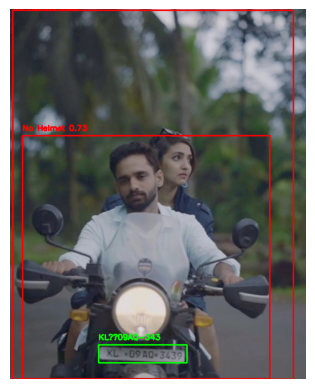


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


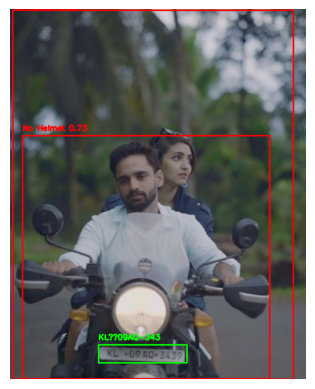


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


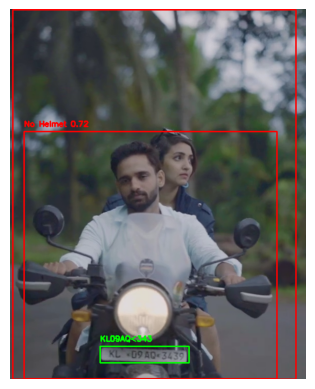


0: 640x640 1 Plate, 2 WithoutHelmets, 100.6ms
Speed: 1.7ms preprocess, 100.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


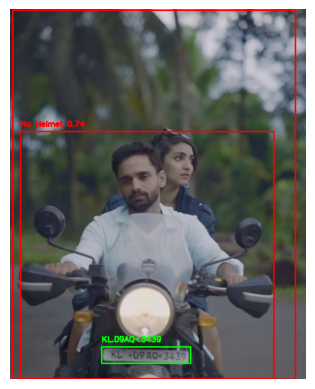


0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


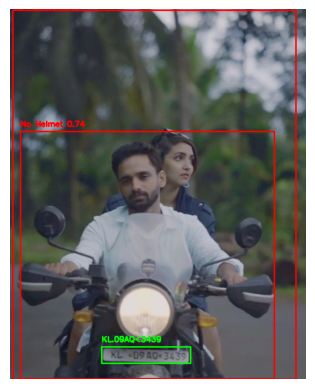


0: 640x640 2 Plates, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


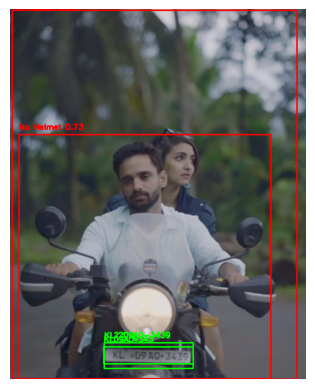


0: 640x640 2 Plates, 2 WithoutHelmets, 100.5ms
Speed: 1.9ms preprocess, 100.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


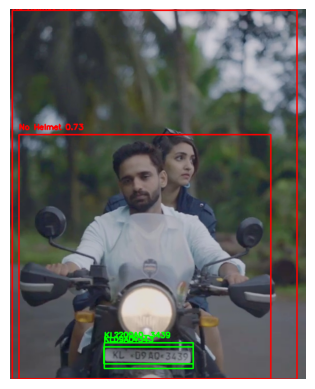


0: 640x640 2 Plates, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.8ms preprocess, 100.5ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.6ms
Speed: 1.8ms preprocess, 100.6ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Plate, 2 WithoutHelmets, 100.5ms
Speed: 1.7ms preprocess, 100.5ms inference, 1.9ms postprocess per image at shape (

In [17]:
import os
import csv
import datetime as dt

class YOLODetector:
    # Class IDs from data.yaml: 0=Plate, 1=WithHelmet, 2=WithoutHelmet
    PLATE_CLASS_ID = 0
    WITH_HELMET_CLASS_ID = 1
    WITHOUT_HELMET_CLASS_ID = 2

    CLASS_NAMES = {
        0: "Plate",
        1: "WithHelmet",
        2: "WithoutHelmet",
    }

    def __init__(self, path_of_model, evidence_dir="/kaggle/working/evidence"):
        self.model = YOLO(path_of_model)

        # --- OCR engine setup ---
        # PaddleOCR 3.x: angle classification is enabled by default in the
        # pipeline, so use_angle_cls is no longer a constructor arg.
        # We installed paddlepaddle==3.2.2 (see install cell) because 3.3.0+
        # has a CPU oneDNN/PIR regression that crashes on every predict()
        # call with:
        #   NotImplementedError: ConvertPirAttribute2RuntimeAttribute not
        #   support [pir::ArrayAttribute<pir::DoubleAttribute>]
        # As a second line of defense (in case the pinned version isn't
        # available in a given environment), we also try to disable MKL-DNN,
        # which is the other documented workaround for this exact crash.
        try:
            self.ocr = PaddleOCR(lang='en', enable_mkldnn=False)
        except TypeError:
            # Older/newer PaddleOCR releases may not expose enable_mkldnn
            # directly on the constructor -- fall back gracefully.
            self.ocr = PaddleOCR(lang='en')

        # --- Evidence generation setup (Task 6 of the problem statement) ---
        # Every violation frame gets: an annotated image saved to disk, and
        # one row in a CSV log with timestamp, violation type, confidence,
        # and plate number (if recovered). This is what "Evidence Generation"
        # actually requires -- annotating in-memory and only plt.imshow()-ing
        # it (the old behavior) doesn't persist anything for later review.
        self.evidence_dir = evidence_dir
        self.images_dir = os.path.join(self.evidence_dir, "images")
        os.makedirs(self.images_dir, exist_ok=True)

        self.log_path = os.path.join(self.evidence_dir, "violations_log.csv")
        self._log_fields = [
            "frame_id", "timestamp", "violation_type",
            "confidence", "plate_number", "evidence_image"
        ]
        # Always start a fresh log for a new detector/video run.
        with open(self.log_path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=self._log_fields)
            writer.writeheader()

        self._frame_counter = 0

    def preprocess(self, image):
        image = np.array(image)
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        image = cv2.resize(image, (640, 640))
        image = image / 255.0
        return image

    def _log_violation(self, frame_id, violation_type, confidence, plate_number, evidence_image_path):
        row = {
            "frame_id": frame_id,
            "timestamp": dt.datetime.now().isoformat(timespec="seconds"),
            "violation_type": violation_type,
            "confidence": round(float(confidence), 4),
            "plate_number": plate_number or "",
            "evidence_image": evidence_image_path,
        }
        with open(self.log_path, "a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=self._log_fields)
            writer.writerow(row)

    def predict_frame(self, frame):
        self._frame_counter += 1
        frame_id = self._frame_counter

        original_image = frame.copy()
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        preprocessed_image = self.preprocess(image)

        # Convert back to PIL Image for YOLO model compatibility
        preprocessed_image = (preprocessed_image * 255).astype(np.uint8)
        image = Image.fromarray(preprocessed_image)

        # Predict and process results using the YOLO model
        results = self.model(image)
        if results is None or len(results[0].boxes) == 0:
            return original_image, [], []

        detections = results[0].boxes.xyxy
        class_ids = results[0].boxes.cls
        confidences = results[0].boxes.conf

        plate_numbers = []
        violations_this_frame = []  # (violation_type, confidence) pairs

        without_helmet_detected = any(
            int(cls) == self.WITHOUT_HELMET_CLASS_ID for cls in class_ids
        )

        # Log every WithoutHelmet detection as its own violation record,
        # even if no plate is recovered -- the violation itself shouldn't
        # be lost just because OCR failed or no plate was visible in frame.
        for box, class_id, confidence in zip(detections, class_ids, confidences):
            if int(class_id) == self.WITHOUT_HELMET_CLASS_ID:
                violations_this_frame.append(("helmet_non_compliance", float(confidence)))
                scale_x = original_image.shape[1] / 640
                scale_y = original_image.shape[0] / 640
                x1, y1, x2, y2 = (box.cpu().numpy() * [scale_x, scale_y, scale_x, scale_y]).round().astype(int)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(original_image.shape[1], x2), min(original_image.shape[0], y2)
                cv2.rectangle(original_image, (x1, y1), (x2, y2), (0, 0, 255), 2)
                cv2.putText(original_image, f"No Helmet {confidence:.2f}", (x1, max(0, y1 - 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

        for box, class_id, confidence in zip(detections, class_ids, confidences):
            plate_number = None
            if int(class_id) == self.PLATE_CLASS_ID and without_helmet_detected:
                scale_x = original_image.shape[1] / 640
                scale_y = original_image.shape[0] / 640
                x1, y1, x2, y2 = (box.cpu().numpy() * [scale_x, scale_y, scale_x, scale_y]).round().astype(int)

                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(original_image.shape[1], x2), min(original_image.shape[0], y2)

                plate_region = original_image[y1:y2, x1:x2]
                if plate_region is None or plate_region.size == 0:
                    continue

                try:
                    ocr_results = self.ocr.predict(plate_region)
                    text = ''.join(
                        ''.join(res.get('rec_texts', []))
                        for res in ocr_results
                    )
                    plate_number = text.strip()
                    if len(plate_number) >= 9:
                        plate_numbers.append(plate_number)
                except Exception as e:
                    print(f"Error during OCR processing: {e}")

                cv2.rectangle(original_image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(original_image, plate_number if plate_number else "", (x1, y1 - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        # Persist evidence: one annotated image + one CSV row per violation
        # detected in this frame (helmet violations are the trigger here;
        # the recovered plate number, if any, is attached to each row).
        if violations_this_frame:
            image_filename = f"frame_{frame_id:06d}.jpg"
            image_path = os.path.join(self.images_dir, image_filename)
            cv2.imwrite(image_path, original_image)

            best_plate = plate_numbers[0] if plate_numbers else None
            for violation_type, confidence in violations_this_frame:
                self._log_violation(frame_id, violation_type, confidence, best_plate, image_path)

        return original_image, plate_numbers, violations_this_frame

    def process_video(self, video_path, display=True, max_display_frames=None):
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise ValueError(f"Cannot open video file {video_path}")

        all_plate_numbers = set()
        total_violations = 0
        displayed = 0

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            annotated_frame, plate_numbers, violations = self.predict_frame(frame)
            if plate_numbers:
                all_plate_numbers.update(plate_numbers)
            total_violations += len(violations)

            if display and (max_display_frames is None or displayed < max_display_frames):
                plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
                plt.axis('off')
                plt.show()
                displayed += 1

        cap.release()

        print(f"\nProcessed video: {video_path}")
        print(f"Total violation records: {total_violations}")
        print(f"Unique plate numbers recovered: {len(all_plate_numbers)}")
        for plate in all_plate_numbers:
            print(" -", plate)
        print(f"\nEvidence images saved to: {self.images_dir}")
        print(f"Violation log saved to:   {self.log_path}")

        return all_plate_numbers

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Auto-discover best.pt and 22.mp4 under /kaggle/input rather than hardcoding
# a path, since dataset mount paths can vary (e.g. nested under datasets/<user>/...).
import glob as _glob

_model_candidates = _glob.glob("/kaggle/input/**/best.pt", recursive=True)
_video_candidates = _glob.glob("/kaggle/input/**/22.mp4", recursive=True)

if not _model_candidates:
    raise FileNotFoundError("Could not find best.pt under /kaggle/input. Check the dataset is attached.")
if not _video_candidates:
    raise FileNotFoundError("Could not find 22.mp4 under /kaggle/input. Check the dataset is attached.")

path_of_model = _model_candidates[0]
path_of_video = _video_candidates[0]
print("Using model:", path_of_model)
print("Using video:", path_of_video)

detector = YOLODetector(path_of_model)

# Process video, save annotated evidence images + violations_log.csv,
# and display a sample of annotated frames inline.
recovered_plates = detector.process_video(path_of_video, display=True, max_display_frames=15)


# ***Explore the project's [GitHub repository](https://github.com/P-Darabi/Helmet-Violations) for detailed explanations, complete code implementations, and additional resources.***